## preprocess

### load dataset
    |1|fish |2|reptiles |
    |3|arthropoda |4|corals |
    |5|mollusk |6|plants |
    |7|ruins |8|garbage |
    |9|human |10|robots |

In [25]:
import json, os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

image_dir = "Dataset/img"
annotation_dir = "Dataset/annotations"

train_json_path = os.path.join(
    annotation_dir,
    "multiclass_train.json"
)

test_json_path = os.path.join(
    annotation_dir,
    "multiclass_test.json"
)

with open(train_json_path, "r") as f:
    data = json.load(f)

with open(test_json_path, "r") as f:
    test_data = json.load(f)

print(data.keys())
print(test_data.keys())

dict_keys(['images', 'type', 'annotations', 'categories'])
dict_keys(['images', 'type', 'annotations', 'categories'])


In [26]:
# from collections import Counter

# resolution_count = Counter()

# for image_info in data["images"]:
#     width = image_info["width"]
#     height = image_info["height"]

#     resolution_count[(width, height)] += 1

# for resolution, count in resolution_count.most_common():
#     print(f"{resolution[0]} × {resolution[1]} : {count} 張")

### img mask

In [27]:
from collections import defaultdict
from PIL import Image
from pycocotools import mask as maskUtils
from tqdm import tqdm
import numpy as np
import os

SIZE = (256, 256)

def create_mask(image_info, anns):
    height, width = image_info["height"], image_info["width"]
    semantic_mask = np.zeros((height, width), dtype=np.uint8)

    for ann in anns:
        rles = maskUtils.frPyObjects(ann["segmentation"], height, width)
        mask = maskUtils.decode(rles)

        if mask.ndim == 3:
            mask = mask.max(axis=2)  # 合併同一物件的所有多邊形

        semantic_mask[mask > 0] = ann["category_id"]

    return semantic_mask


def load_split(coco, image_dir, size=SIZE):
    # 先建索引：image_id -> annotations，只掃一次
    anns_by_img = defaultdict(list)
    for ann in coco["annotations"]:
        anns_by_img[ann["image_id"]].append(ann)

    images, masks = [], []

    for info in tqdm(coco["images"]):
        img = Image.open(os.path.join(image_dir, info["file_name"])).convert("RGB")
        images.append(np.array(img.resize(size, Image.BILINEAR)))

        mask = create_mask(info, anns_by_img[info["id"]])
        masks.append(np.array(Image.fromarray(mask).resize(size, Image.NEAREST)))

    return np.stack(images), np.stack(masks)


train_images, train_masks = load_split(data, image_dir)
test_images, test_masks = load_split(test_data, image_dir)

print(train_images.shape, train_masks.shape)
print(test_images.shape, test_masks.shape)

  0%|          | 0/8038 [00:00<?, ?it/s]

100%|██████████| 2010/2010 [00:17<00:00, 112.25it/s]


(8038, 256, 256, 3) (8038, 256, 256)
(2010, 256, 256, 3) (2010, 256, 256)


In [28]:
rng = np.random.default_rng(42)  # 固定 seed，結果可重現
perm = rng.permutation(len(train_images))

n_val = int(len(perm) * 0.1)  # 10% 當驗證集
val_idx, train_idx = perm[:n_val], perm[n_val:]

val_images, val_masks = train_images[val_idx], train_masks[val_idx]
train_images, train_masks = train_images[train_idx], train_masks[train_idx]

print(len(train_images), len(val_images), len(test_images))

7235 803 2010


## U-net training

### establish dataset

In [29]:
import torch
from torch.utils.data import Dataset, DataLoader
import random

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        
class UIIS10KDataset(Dataset):
    def __init__(self, images, masks, augment = False):
        self.images = images  # (N, H, W, 3) uint8
        self.masks = masks    # (N, H, W)    uint8
        self.augment = augment 

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx].copy()
        mask = self.masks[idx].copy()
        
        if self.augment:
            # 水平翻轉，image 和 mask 要同步翻，機率 50%
            if random.random() < 0.5:
                image = image[:, ::-1, :].copy()
                mask = mask[:, ::-1].copy()
            
            # # 上下翻轉
            # if random.random() < 0.5:
            #     image = image[::-1, :, :].copy()
            #     mask = mask[::-1, :].copy()

            # 亮度 / 對比擾動，只動 image
            # if random.random() < 0.5:
            #     brightness = random.uniform(0.8, 1.2)
            #     contrast = random.uniform(0.8, 1.2)
            #     mean = image.mean()
            #     image = (image.astype(np.float32) - mean) * contrast + mean * brightness
            #     image = np.clip(image, 0, 255).astype(np.uint8)

        image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0
        image = (image - IMAGENET_MEAN) / IMAGENET_STD
        mask = torch.from_numpy(mask).long()
        
        return image, mask


train_dataset = UIIS10KDataset(train_images, train_masks, augment=True)
val_dataset = UIIS10KDataset(val_images, val_masks, augment=False)
test_dataset = UIIS10KDataset(test_images, test_masks, augment=False)

loader_kwargs = dict(num_workers=2, pin_memory=True)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, **loader_kwargs)

### build model 

In [30]:
import torch
import torch.nn as nn


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Dropout2d(dropout),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, num_classes=11, dropout=0.2):
        super().__init__()

        self.enc1 = DoubleConv(3, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(512, 1024, dropout=dropout)

        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)
        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        self.out = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out(d1)

In [31]:
import torch.nn.functional as F

class CEDiceLoss(nn.Module):
    def __init__(self, num_classes, dice_weight=1.0, eps=1e-6, class_weights=None):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights)
        self.num_classes = num_classes
        self.dice_weight = dice_weight
        self.eps = eps

    def forward(self, logits, target):
        ce = self.ce(logits, target)

        prob = F.softmax(logits.float(), dim=1)  # (N, C, H, W)
        target_onehot = F.one_hot(target, self.num_classes).permute(0, 3, 1, 2).float()

        dims = (0, 2, 3)
        inter = (prob * target_onehot).sum(dims)
        union = prob.sum(dims) + target_onehot.sum(dims)
        dice_per_class = (2 * inter + self.eps) / (union + self.eps)

        present = target_onehot.sum(dims) > 0
        
        if present.any():
            dice_loss = 1 - dice_per_class[present].mean()
        else :
            dice_loss = 1 - dice_per_class.mean()

        return ce + self.dice_weight * dice_loss

In [32]:
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = False

NUM_CLASSES = len(data["categories"]) + 1
counts = np.bincount(train_masks.ravel(), minlength=NUM_CLASSES)
freq = counts / counts.sum()
class_weights = torch.tensor(1.0 / np.log(1.02 + freq), dtype=torch.float32)
class_weights = torch.clamp(class_weights, max=class_weights.median() * 5)
class_weights = class_weights.to(device)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES,
).to(device)

if torch.cuda.device_count() > 1:
    print(f"使用 {torch.cuda.device_count()} 張 GPU")
    model = nn.DataParallel(model)
    
criterion = CEDiceLoss(num_classes=NUM_CLASSES, class_weights=class_weights)
optimizer = torch.optim.Adam([
    {"params": model.encoder.parameters(), "lr": 1e-5},
    {"params": model.decoder.parameters(), "lr": 1e-4},
    {"params": model.segmentation_head.parameters(), "lr": 1e-4},
])
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

print(device)

cuda


In [33]:
def run_epoch(loader, train=True):
    model.train(train)
    total_loss = 0.0
    intersection = torch.zeros(NUM_CLASSES, dtype=torch.long, device=device)
    union = torch.zeros(NUM_CLASSES, dtype=torch.long, device=device)

    with torch.set_grad_enabled(train):
        for images, masks in loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", enabled=use_amp):
                output = model(images)
                loss = criterion(output, masks)

            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item()

            pred = output.argmax(dim=1)
            for c in range(NUM_CLASSES):
                pred_c = pred == c
                gt_c = masks == c
                intersection[c] += (pred_c & gt_c).sum()
                union[c] += (pred_c | gt_c).sum()
    
    valid_classes = union > 0
    iou_per_class_t = intersection.float() / (union.float() + 1e-8)

    miou = iou_per_class_t[valid_classes].mean().item()
    iou_per_class = iou_per_class_t.cpu().numpy()

    return {
        "loss": total_loss / len(loader),
        "iou_per_class": iou_per_class,
        "miou": miou,
    }

In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=5
)
num_epochs = 30
best_iou = -1.0

history = {
    "train_loss": [],
    "val_loss": [],
    "miou": [],
    "iou_per_class": [],
}


for epoch in range(num_epochs):
    tr = run_epoch(train_loader, train=True)
    va = run_epoch(val_loader, train=False)

    history["train_loss"].append(tr["loss"])
    history["val_loss"].append(va["loss"])
    history["miou"].append(va["miou"])
    history["iou_per_class"].append(va["iou_per_class"])
    
    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"train loss: {tr['loss']:.4f} | "
        f"val loss: {va['loss']:.4f} | "
        f"mIoU: {va['miou']:.4f}"
    )
    
    scheduler.step(va["miou"])

    if va["miou"] > best_iou:
        best_iou = va["miou"]
        torch.save(model.state_dict(), "best_unet.pth")
        print("  -> saved best model")

Epoch [1/50] train loss: 2.5244 | val loss: 1.9792 | mIoU: 0.2341
  -> saved best model
Epoch [2/50] train loss: 1.9076 | val loss: 1.6919 | mIoU: 0.3229
  -> saved best model
Epoch [3/50] train loss: 1.6678 | val loss: 1.5830 | mIoU: 0.3488
  -> saved best model
Epoch [4/50] train loss: 1.5074 | val loss: 1.5103 | mIoU: 0.3829
  -> saved best model
Epoch [5/50] train loss: 1.3834 | val loss: 1.5264 | mIoU: 0.3692
Epoch [6/50] train loss: 1.2844 | val loss: 1.4960 | mIoU: 0.3984
  -> saved best model
Epoch [7/50] train loss: 1.1855 | val loss: 1.4903 | mIoU: 0.3990
  -> saved best model
Epoch [8/50] train loss: 1.1152 | val loss: 1.5260 | mIoU: 0.4095
  -> saved best model
Epoch [9/50] train loss: 1.0334 | val loss: 1.5143 | mIoU: 0.4254
  -> saved best model
Epoch [10/50] train loss: 0.9619 | val loss: 1.5752 | mIoU: 0.4063
Epoch [11/50] train loss: 0.9171 | val loss: 1.6183 | mIoU: 0.4105
Epoch [12/50] train loss: 0.8479 | val loss: 1.6774 | mIoU: 0.4178
Epoch [13/50] train loss: 0.8

KeyboardInterrupt: 

In [35]:
import os
import datetime 
import matplotlib.pyplot as plt

def new_run_dir(run_name=None):
    """建立一個新的 run 資料夾，回傳路徑"""
    timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    name = f"{timestamp}_{run_name}" if run_name else timestamp
    run_dir = os.path.join("Result", name)
    os.makedirs(run_dir, exist_ok=True)
    return run_dir

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        if isinstance(obj, (np.integer, np.floating)):
            return obj.item()
        return super().default(obj)

def save_history(history, run_dir, extra_info=None):
    """把 history 數字存成 json，extra_info 可以放超參數等描述"""
    payload = {"history": history}
    if extra_info:
        payload["info"] = extra_info

    with open(os.path.join(run_dir, "history.json"), "w") as f:
        json.dump(payload, f, indent=2, cls=NumpyEncoder)

def save_test_result(test_result, run_dir, class_names):
    lines = [
        f"Test Loss: {test_result['loss']:.4f}",
        f"Test mIoU: {test_result['miou']:.4f}",
        "",
        "Per-class IoU:",
    ]
    for name, iou in zip(class_names, test_result["iou_per_class"]):
        lines.append(f"{name:12s}: {iou:.4f}")

    text = "\n".join(lines)
    print(text)

    # 存成好讀的文字檔
    with open(os.path.join(run_dir, "test_result.txt"), "w") as f:
        f.write(text)

    # 同時存成 json，方便之後程式化讀取比較
    with open(os.path.join(run_dir, "test_result.json"), "w") as f:
        json.dump(test_result, f, indent=2, cls=NumpyEncoder)
        
def plot_and_save(history, run_dir, title_prefix=""):
    """畫 loss 和 mIoU 兩張圖，存到該 run 的資料夾"""
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], label="train loss")
    axes[0].plot(epochs, history["val_loss"], label="val loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"{title_prefix} Loss")
    axes[0].legend()

    axes[1].plot(epochs, history["miou"], label="mIoU")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Score")
    axes[1].set_title(f"{title_prefix} mIoU")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(run_dir, "loss_miou_curve.png"), dpi=150, bbox_inches="tight")
    plt.show()
    

本次結果存放於: Result/20261012_122201_multiclass_dropout01_noWD


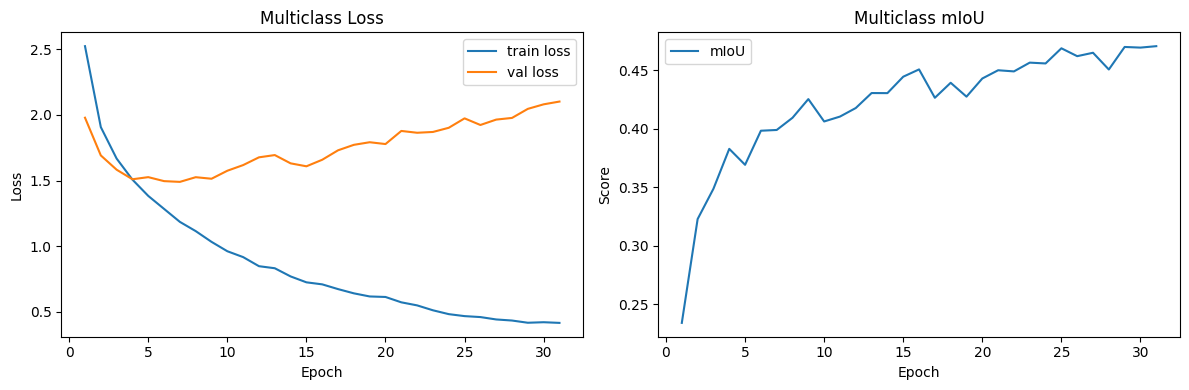

In [36]:
run_dir = new_run_dir("multiclass_dropout01_noWD")
print("本次結果存放於:", run_dir)

plot_and_save(history, run_dir, title_prefix="Multiclass")

save_history(
    history,
    run_dir,
    extra_info={
        "num_classes": NUM_CLASSES,
        "dropout": 0.2,
        "weight_decay": None,
        "lr": 1e-4,
        "batch_size": 16,
        "num_epochs": num_epochs,
        "best_miou": best_iou,
        "scheduler": "ReduceLROnPlateau(factor=0.5, patience=5)",
        "notes": "提高epoch~50，增加分組lr",
    },
)

In [37]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import torch

model.load_state_dict(torch.load("best_unet.pth", map_location=device))
model.eval()

id_to_name = {0: "background"}
for c in data["categories"]:
    id_to_name[c["id"]] = c["name"]

plants_id = next(c["id"] for c in data["categories"] if c["name"] == "plants")
arthropoda_id = next(c["id"] for c in data["categories"] if c["name"] == "arthropoda")

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def denormalize(image):
    return (image * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1)

def show_predictions(dataset, n=6, only_object=True, target_class_id=None, seed=0, save_path=None):
    masks_flat = dataset.masks.reshape(len(dataset), -1)

    if target_class_id is not None:
        candidates = np.where((masks_flat == target_class_id).any(axis=1))[0]
        print(f"含有 {id_to_name.get(target_class_id, target_class_id)} 的樣本數: {len(candidates)}")
    elif only_object:
        has_object = masks_flat.max(axis=1) > 0
        candidates = np.where(has_object)[0]
    else:
        candidates = np.arange(len(dataset))

    n = min(n, len(candidates))
    idxs = np.random.default_rng(seed).choice(candidates, n, replace=False)

    cmap = plt.get_cmap("tab20")
    norm = plt.Normalize(vmin=0, vmax=NUM_CLASSES - 1)

    fig, axes = plt.subplots(n, 3, figsize=(10, 3 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    for row, i in enumerate(idxs):
        image, mask = dataset[i]

        with torch.no_grad():
            pred = model(image.unsqueeze(0).to(device)).argmax(dim=1)[0].cpu()

        axes[row, 0].imshow(denormalize(image).permute(1, 2, 0))
        axes[row, 1].imshow(mask, vmin=0, vmax=NUM_CLASSES - 1, cmap="tab20")
        axes[row, 2].imshow(pred, vmin=0, vmax=NUM_CLASSES - 1, cmap="tab20")

        if row == 0:
            axes[row, 0].set_title("Image")
            axes[row, 1].set_title("Ground Truth")
            axes[row, 2].set_title("Prediction")

        for ax in axes[row]:
            ax.axis("off")

    present_ids = set()
    for i in idxs:
        _, mask = dataset[i]
        present_ids.update(np.unique(mask.numpy()).tolist())

    handles = [
        mpatches.Patch(color=cmap(norm(cid)), label=id_to_name.get(cid, f"id {cid}"))
        for cid in sorted(present_ids)
    ]

    fig.legend(
        handles=handles,
        loc="lower center",
        ncol=min(len(handles), 6),
        bbox_to_anchor=(0.5, -0.1 / n),
        frameon=False,
    )

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

## Test

Test Dataset Results
Test Loss: 1.9465
Test mIoU: 0.4852

Per-class IoU:
Background  : 0.8025
fish        : 0.6559
reptiles    : 0.6299
arthropoda  : 0.2467
corals      : 0.3984
mollusk     : 0.4255
plants      : 0.1391
ruins       : 0.4795
garbage     : 0.3765
human       : 0.6718
robots      : 0.5116


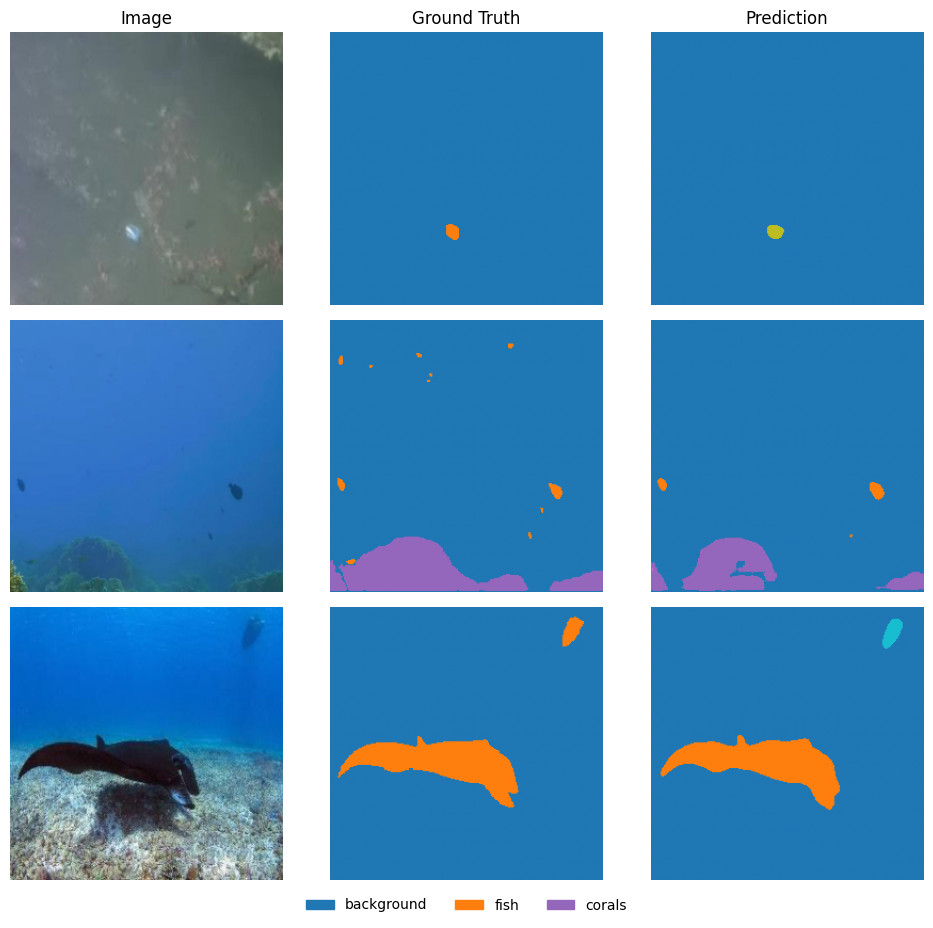

In [39]:
### Test Dataset Evaluation

model.load_state_dict(
    torch.load("best_unet.pth", map_location=device)
)

model.eval()

test_result = run_epoch(test_loader, train=False)

print("=" * 40)
print("Test Dataset Results")
print("=" * 40)

category_names = {0: "Background"}
for category in data["categories"]:
    category_names[category["id"]] = category["name"]

class_names = [category_names.get(i, str(i)) for i in range(NUM_CLASSES)]

# 存進跟這次訓練同一個 run_dir
save_test_result(test_result, run_dir, class_names)

show_predictions(
    test_dataset, n=3, only_object=False, seed=0,
    save_path=os.path.join(run_dir, "test_predictions.png"),
)